# Sample quality control

Assess library content, sample structure, and cross-fraction concordance.


In [1]:
import os
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from pydeseq2.dds import DeseqDataSet
from sklearn.decomposition import PCA

N_CPUS = min(4, os.cpu_count() or 1)
FRACTIONS = ('Input', 'Monosome', 'Polysome')
PREFIXES = {
    'Input': 'input',
    'Monosome': 'mono',
    'Polysome': 'poly',
}
CONDITION_COLORS = {
    'ASD': '#D55E00',
    'Unaffected': '#0072B2',
}
FRACTION_COLORS = dict(zip(FRACTIONS, sns.color_palette('colorblind', 3)))

sns.set_theme(style = 'ticks', context = 'notebook')


In [2]:
# Locate the project and read one gene matrix.


def find_root(start: Path) -> Path:
    for path in (start, *start.parents):
        if (path / 'data').is_dir():
            return path
    raise FileNotFoundError('Could not find the project data directory.')


ROOT = find_root(Path.cwd().resolve())
DATA_DIR = ROOT / 'data'
RESULTS_DIR = ROOT / 'results'
RESULTS_DIR.mkdir(exist_ok = True)
metadata = pd.read_csv(DATA_DIR / 'metadata.tsv', sep = '\t', dtype = 'string')
metadata = metadata.set_index('sampleId')
sample_ids = metadata.index.tolist()


def load_matrix(fraction: str, filename: str) -> pd.DataFrame:
    path = DATA_DIR / fraction / filename
    table = pd.read_csv(path, sep = '\t')
    columns = [f'{PREFIXES[fraction]}{sample_id}' for sample_id in sample_ids]
    missing = {'gene_id', *columns}.difference(table.columns)

    if missing:
        raise ValueError(f'{path.name} is missing columns: {sorted(missing)}')

    matrix = table.set_index('gene_id').loc[:, columns]
    matrix.columns = sample_ids
    matrix.index.name = 'geneId'
    matrix.columns.name = 'sampleId'

    return matrix


In [3]:
# Load the matrices used for complementary QC views.

counts = {}
length_scaled_counts = {}
tpm = {}

for fraction in FRACTIONS:
    counts[fraction] = load_matrix(
        fraction,
        'salmon.merged.gene_counts.tsv',
    )
    length_scaled_counts[fraction] = load_matrix(
        fraction,
        'salmon.merged.gene_counts_length_scaled.tsv',
    )
    tpm[fraction] = load_matrix(
        fraction,
        'salmon.merged.gene_tpm.tsv',
    )

    if not counts[fraction].index.equals(length_scaled_counts[fraction].index):
        raise ValueError(f'Count matrices are misaligned in {fraction}.')
    if not counts[fraction].index.equals(tpm[fraction].index):
        raise ValueError(f'TPM is misaligned with counts in {fraction}.')


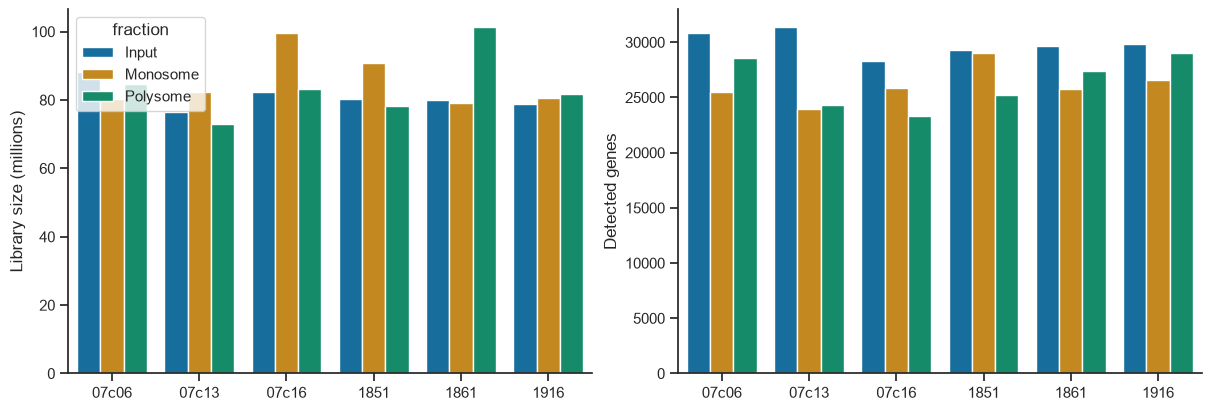

,sampleId,condition,fraction,librarySizeMillions,detectedGenes
0,07c06,Unaffected,Input,88.255802,30844
1,07c13,Unaffected,Input,76.430878,31413
2,07c16,Unaffected,Input,82.264185,28276
3,1851,ASD,Input,80.342752,29292
4,1861,ASD,Input,79.871183,29628
5,1916,ASD,Input,78.697454,29855
6,07c06,Unaffected,Monosome,80.393505,25518
7,07c13,Unaffected,Monosome,82.273503,23989
8,07c16,Unaffected,Monosome,99.532256,25865
9,1851,ASD,Monosome,90.743924,29068


In [4]:
# Compare library depth and gene detection without defining exclusion thresholds.

records = []

for fraction in FRACTIONS:
    for sample_id in sample_ids:
        records.append({
            'sampleId': sample_id,
            'condition': metadata.loc[sample_id, 'condition'],
            'fraction': fraction,
            'librarySizeMillions': counts[fraction][sample_id].sum() / 1e6,
            'detectedGenes': counts[fraction][sample_id].gt(0).sum(),
        })

library_qc = pd.DataFrame(records)

figure, axes = plt.subplots(1, 2, figsize = (12, 4), constrained_layout = True)
sns.barplot(
    data = library_qc,
    x = 'sampleId',
    y = 'librarySizeMillions',
    hue = 'fraction',
    palette = FRACTION_COLORS,
    ax = axes[0],
)
sns.barplot(
    data = library_qc,
    x = 'sampleId',
    y = 'detectedGenes',
    hue = 'fraction',
    palette = FRACTION_COLORS,
    ax = axes[1],
)
axes[0].set(xlabel = '', ylabel = 'Library size (millions)')
axes[1].set(xlabel = '', ylabel = 'Detected genes')
axes[1].legend_.remove()
sns.despine()
plt.show()

display(library_qc)


In [5]:
# Fit blind variance-stabilizing transformations independently by fraction.


def vst(matrix: pd.DataFrame) -> pd.DataFrame:
    X = np.rint(matrix.T).astype('int64')
    X = X.loc[:, X.sum(axis = 0).gt(0)]
    dds = DeseqDataSet(
        counts = X,
        metadata = metadata,
        design = '~1',
        refit_cooks = False,
        n_cpus = N_CPUS,
        quiet = True,
    )
    dds.vst(use_design = False)

    return pd.DataFrame(
        dds.layers['vst_counts'],
        index = X.index,
        columns = X.columns,
    )


vst_counts = {
    fraction: vst(length_scaled_counts[fraction])
    for fraction in FRACTIONS
}


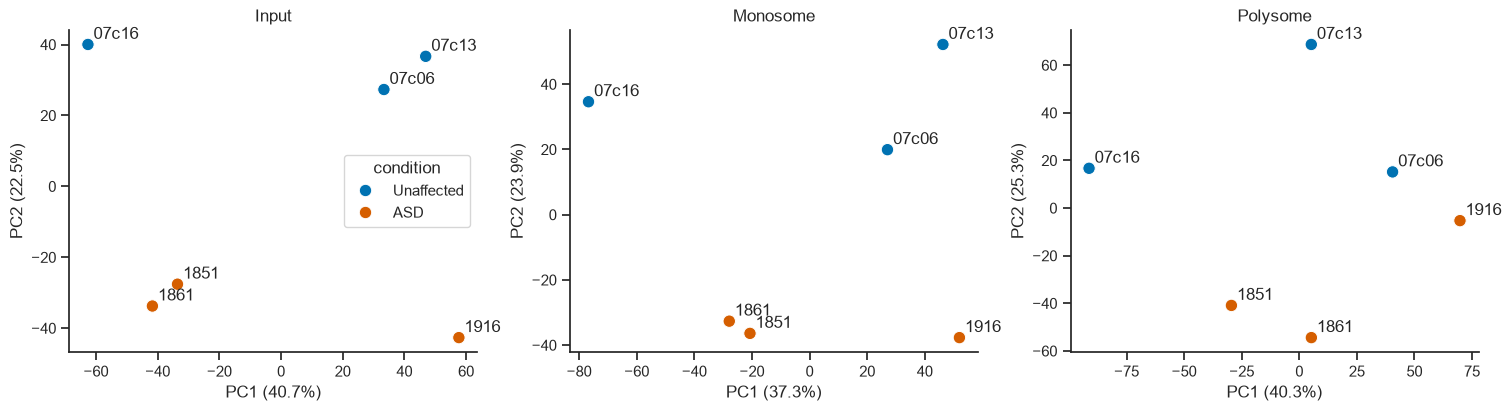

In [6]:
# Examine sample structure within each fraction.


def pca_scores(X: pd.DataFrame) -> tuple[pd.DataFrame, np.ndarray]:
    model = PCA(n_components = 2)
    scores = model.fit_transform(X)
    scores = pd.DataFrame(scores, index = X.index, columns = ['PC1', 'PC2'])

    return scores, model.explained_variance_ratio_ * 100


figure, axes = plt.subplots(1, 3, figsize = (15, 4), constrained_layout = True)

for index, fraction in enumerate(FRACTIONS):
    scores, variance = pca_scores(vst_counts[fraction])
    scores = scores.join(metadata['condition'])
    axis = axes[index]
    sns.scatterplot(
        data = scores,
        x = 'PC1',
        y = 'PC2',
        hue = 'condition',
        palette = CONDITION_COLORS,
        s = 80,
        legend = index == 0,
        ax = axis,
    )
    for sample_id, row in scores.iterrows():
        axis.annotate(
            sample_id,
            (row['PC1'], row['PC2']),
            xytext = (4, 4),
            textcoords = 'offset points',
        )
    axis.set(
        title = fraction,
        xlabel = f'PC1 ({variance[0]:.1f}%)',
        ylabel = f'PC2 ({variance[1]:.1f}%)',
    )

sns.despine()
plt.show()


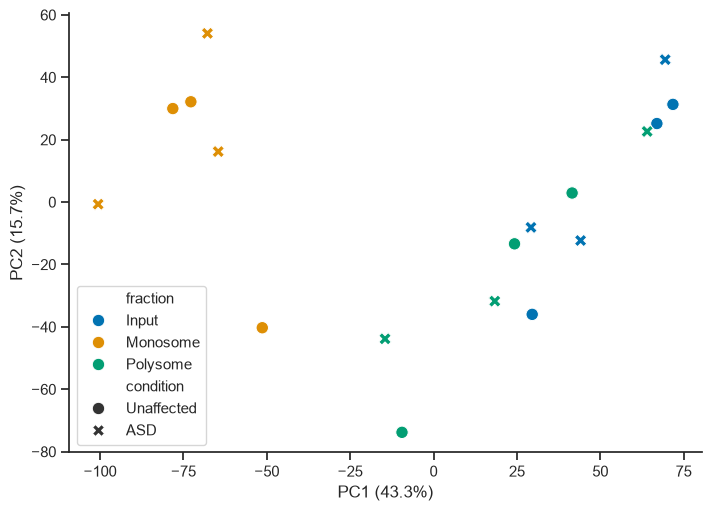

In [7]:
# Visualize the expected global separation of RNA fractions using log-TPM.

combined_tpm = pd.concat(tpm, axis = 1)
combined_tpm.columns.names = ['fraction', 'sampleId']
X = np.log2(combined_tpm.T + 1)
X = X.loc[:, X.var(axis = 0).gt(0)]
scores, variance = pca_scores(X)
scores = scores.reset_index()
scores['condition'] = scores['sampleId'].map(metadata['condition'])

figure, axis = plt.subplots(figsize = (7, 5), constrained_layout = True)
sns.scatterplot(
    data = scores,
    x = 'PC1',
    y = 'PC2',
    hue = 'fraction',
    style = 'condition',
    palette = FRACTION_COLORS,
    s = 80,
    ax = axis,
)
axis.set(
    xlabel = f'PC1 ({variance[0]:.1f}%)',
    ylabel = f'PC2 ({variance[1]:.1f}%)',
)
sns.despine()
plt.show()


In [8]:
# Compare sample-specific deviations after removing each fraction's mean profile.

records = []

for first, second in combinations(FRACTIONS, 2):
    X = np.log2(tpm[first] + 1)
    Y = np.log2(tpm[second] + 1)
    X = X.sub(X.mean(axis = 1), axis = 0).T
    Y = Y.sub(Y.mean(axis = 1), axis = 0).T
    matrix = np.corrcoef(X, Y)[:len(sample_ids), len(sample_ids):]

    for index, sample_id in enumerate(sample_ids):
        best = int(np.argmax(matrix[index]))
        records.append({
            'fractionPair': f'{first}-{second}',
            'sampleId': sample_id,
            'matchedCorrelation': matrix[index, index],
            'bestMatch': sample_ids[best],
            'matchedIsBest': best == index,
        })

sample_matching = pd.DataFrame(records)
display(sample_matching)


,fractionPair,sampleId,matchedCorrelation,bestMatch,matchedIsBest
0,Input-Monosome,07c06,0.416318,07c06,True
1,Input-Monosome,07c13,0.382856,07c06,False
2,Input-Monosome,07c16,0.551261,07c16,True
3,Input-Monosome,1851,0.370544,1851,True
4,Input-Monosome,1861,0.616468,1861,True
5,Input-Monosome,1916,0.654541,1916,True
6,Input-Polysome,07c06,0.553749,07c06,True
7,Input-Polysome,07c13,0.466052,07c13,True
8,Input-Polysome,07c16,0.592919,07c16,True
9,Input-Polysome,1851,0.461321,1851,True


In [9]:
# Save reusable QC tables.

library_qc.to_csv(
    RESULTS_DIR / 'libraryQc.tsv',
    sep = '\t',
    index = False,
)
sample_matching.to_csv(
    RESULTS_DIR / 'sampleMatching.tsv',
    sep = '\t',
    index = False,
)
